##  CaliPlant AI — Deep Engineering & Model Evolution Journal
**Author:**    Aspiring Machine Learning Engineer & Data Analyst
**Project Scope:**    Multi-Class Image Classification Pipeline for 51 Native California Plant Species  
**Infrastructure Framework:**    TensorFlow 2.x / Keras Functional API  

---

###  Section 1: Executive Engineering Synopsis
The objective of the CaliPlant AI product is to construct an optimized, high-fidelity computer vision system tailored to classify 51 native California plant species from highly complex visual data (leaf venation patterns, edge serrations, and macro floral characteristics). 

This journal chronologically documents the entire end-to-end development lifecycle across five iterative phases (V1 to V5- till now). 
It deep-dives into the technical failures, architectural missteps, environment bottlenecks, and the precise engineering workarounds deployed to systematically scale the model from a fragile baseline to a resilient, deeply fine-tuned production network.

## Phase 1: Model V1 — The Custom CNN Scratch Architecture

### 1. Design & Core Technical Implementation Strategy
Instead of relying immediately on heavy pre-trained transfer learning architectures, in this project I initially started by constructing a custom Convolutional Neural Network (CNN) from scratch. The primary engineering goal was to evaluate if a fundamental convolutional network could extract basic geometric features, leaf margins, and shape primitives directly from our unique target distribution without external weight bias ?

* **Structural Setup:**
  * Configured a basic sequential model featuring three consecutive `Conv2D` layers paired with `MaxPooling2D` layers to execute downstream feature extraction and spatial downsampling.
  * Added a flattening layer to transition multidimensional feature maps into a 1D vector.
  * Deployed a single dense hidden layer with 256 nodes utilizing `ReLU` activations.
  * Terminated the network with a `Dense(51, activation='softmax')` layer to handle multi-class probabilities across the entire target list of 51 species.
---
* **Data Flow:** Raw image arrays were resized to a standard target resolution of `(224, 224, 3)`. Images were rescaled by `1./255` using a basic `ImageDataGenerator` setup without any spatial distortions.
---

```python
# 1. Custom CNN Sequential Design from scratch
import os
import tensorflow as tf
from tensorflow.keras import layers, models                                  # type: ignore 
from tensorflow.keras.preprocessing.image import ImageDataGenerator          # type: ignore 

model = models.Sequential([
    # First Convolutional Block: Extracts low-level spatial features and edge primitives
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    layers.MaxPooling2D((2, 2)),
    
    # Second Convolutional Block: Extracts mid-level complex geometric properties and shape primitives
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Third Convolutional Block: Extracts high-level semantic structures and fine leaf textures
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Flattening Layer: Converts multidimensional feature maps into a 1D feature vector for classification
    layers.Flatten(),
    
    # 3. Dense Connective Block
    layers.Dense(256, activation='relu'),
    
    # 4. Final Classification Output Layer (Total 51 Output Nodes for 51 Classes)
    layers.Dense(51, activation='softmax')
])

# Ensure target storage folders exist
os.makedirs("04_Models", exist_ok=True)

# Model structure inspection
model.summary()

### 2. Failure Diagnosis & Engineering Bottlenecks
* **The Stagnation Profile:** 
  * The model suffered from intense underfitting. The training loss flattened out at an unacceptably high level after just a few epochs, and both training and validation accuracies stalled near random guess rates.
* **Technical Root Cause Analysis:**
  * **Insufficient Receptive Field & Depth:** A custom 3-layer CNN lacks the depth and architectural capacity required to capture the hyper-specific, microscopic structural characteristics of botanical assets. Features like specialized leaf margins, branching veins, and unique leaf bases cannot be mapped by a shallow network.
  * **Vanishing Gradients & Optimization Failures:** Training a network from randomized weight initializations over 51 unique complex categories from scratch leads to unstable gradient flow, causing the optimization path to get permanently trapped in poor local minima.
---

![WhatsApp Image 2026-06-19 at 11.45.22 AM.jpeg](<attachment:WhatsApp Image 2026-06-19 at 11.45.22 AM.jpeg>)
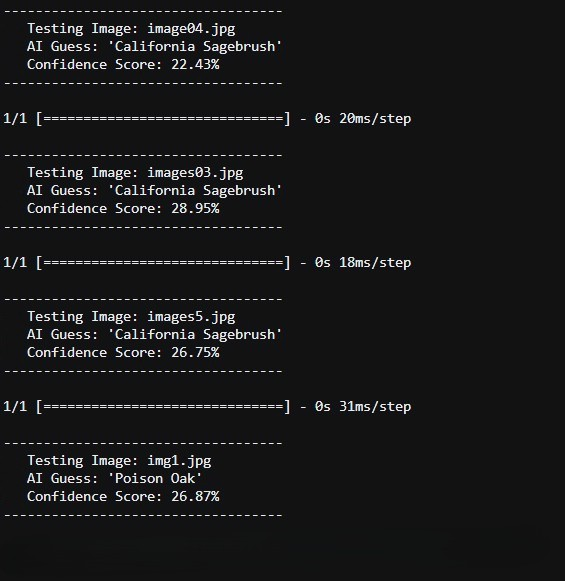

---

## Phase 2: Model V2 — Downscaled Proof of Concept via Frozen layers of MobileNetV2

### 1. The Strategy Pivot (Mitigating Scratch-Model Inadequacies)
* Recognizing that building custom deep topologies from scratch required massive data streams and hyperparameter searches, this project executed a major strategic pivot toward Transfer Learning. Since I did not have a lot of data available for training the model. I had around 100 images per 5 classes of plants. 
* This phase introduced **MobileNetV2**, leveraging its inverted residual blocks and depthwise separable convolutions(150 layers deep.. ya) pre-trained on the ImageNet dataset. To rigorously test this proof of concept, the target distribution was narrowed down to a simplified 5-plant classification task.

### 2. Implementation Specifications & Downscaled Data Flow
* **Input Pipeline Downscaling:** To accelerate training times and minimize memory overhead, input image shapes were restricted to a compressed resolution of `(160, 160, 3)`. The configuration deployed a highly volatile `batch_size=4`. Simple variance was introduced via runtime transformations using `rotation_range=20` and `horizontal_flip=True`.
* **Transfer Learning Core Integration:**

  ```python
  from tensorflow.keras.applications import MobileNetV2
  from tensorflow.keras import layers, models

  base_model = MobileNetV2(input_shape=(160, 160, 3), include_top=False, weights='imagenet')
  base_model.trainable = False  # Hard-freezing the pre-trained ImageNet parameter backbone


* **Classification Head Structure:** The output feature maps were passed into a modern Sequential head wrapper:
GlobalAveragePooling2D() ----->  Dropout(0.2) (to penalize node co-dependency) ------>  Dense(5, activation='softmax').
The system was compiled using the standard Adam optimizer with default learning parameters.

 ```python
  # BUILDING CUSTOM HEAD
  model = models.Sequential([
      base_model,
      layers.GlobalAveragePooling2D(), # Data ko simplify karne ke liye
      layers.Dropout(0.2),             # Ratta-mar (Overfitting) rokne ke liye :)
      layers.Dense(5, activation='softmax')
  ])


![WhatsApp Image 2026-06-19 at 1.27.14 PM.jpeg](<attachment:WhatsApp Image 2026-06-19 at 1.27.14 PM.jpeg>)


### 3. Failure Mode & Scaling Bottlenecks
* **The Information Bottleneck:** While the model quickly reached high accuracy on the 5-plant subset, the configuration exposed terminal architectural bottlenecks when attempting to scale.

* **Technical Root Cause Analysis:**

  * Sub-Pixel Dimensional Loss: Compressing raw botanical assets down to a 160x160 pixel matrix stripped away the fine leaf texturing and venation details required to differentiate species.

  * Gradient Instability via Small Batches: A batch_size=4 caused highly volatile gradient steps during backpropagation. This volatility showed that while a frozen architecture with small inputs could memorize a 5-class subset, it would fail to converge on a highly granular, 51-class distribution.
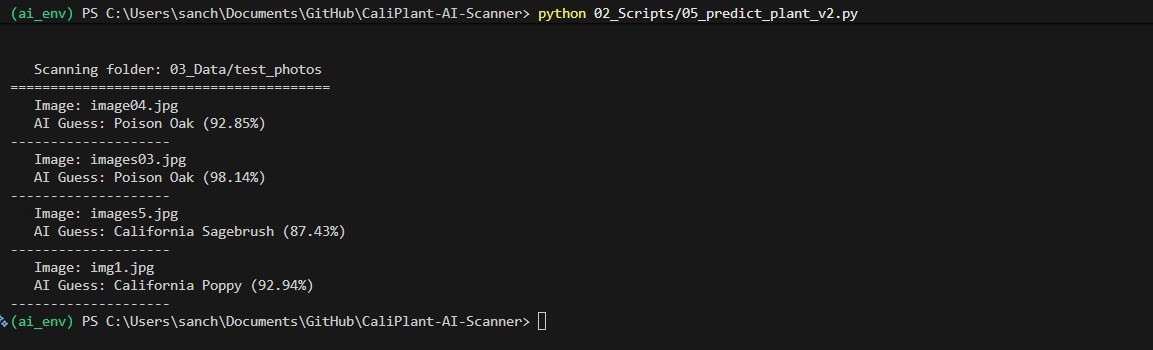

---

## Phase 3: Model V3 — Target Distribution Expansion to 51 Classes & Deep Feature Head Expansion

### 1. The Strategy Pivot (Scaling the Decision Boundaries)
Model V2 successfully validated the structural efficiency of using a pre-trained backbone over a raw scratch network. However, expanding the system to handle the full, real-world target footprint of **51 distinct plant species** required an overhaul of the model's capacity. Model V3 was engineered to handle these expanded decision boundaries by scaling up spatial resolutions, stabilizing batch operations, and heavily augmenting the incoming training data.

### 2. Production Code Pipeline & Data Augmentation Enhancements
* **High-Variance In-Memory Augmentation Engine:** To protect the expanded network from early pixel memorization and over-adaptation, the data flow loader was configured with high-variance geometric transformations to simulate real-world field capture errors:
  ```python
  train_datagen = ImageDataGenerator(
      rescale=1./255,
      rotation_range=30,           # Simulates random rotational variations during field hand-capture
      width_shift_range=0.2,       # Mimics off-center framing anomalies by end users
      height_shift_range=0.2,      # Simulates vertical axis cropping errors
      shear_range=0.2,             # Corrects for angular perspective distortions relative to the leaf plane
      zoom_range=0.2,              # Simulates macro/close-ups versus wide-angle shots
      horizontal_flip=True,        # Leverages the bilateral symmetry of botanical targets
      fill_mode='nearest'          # Smoothly interpolates empty pixels exposed by spatial shifts
  )

* **Architectural Upgrades:** Input spatial parameters were restored to the standard resolution of (224, 224, 3), and training stability was reinforced by setting batch_size=32.

* **Deep Feature Head Engineering:** To handle the complex classification requirements of 51 distinct categories, an intermediate fully connected block was integrated into the top network head:
  * GlobalAveragePooling2D() 
  * Dense(512, activation='relu') 
  * Dropout(0.4) (scaled up to actively force feature redundancy) 
  * Dense(51, activation='softmax').

```python
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), 
    include_top=False, 
    weights='imagenet'
)
base_model.trainable = False  # Keep the "general knowledge" frozen : Initial Layers (0-50),Middle Layers (50-100) & Final Layers (100-154)

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(512, activation='relu'),                        # Increased neurons for 51 classes
    layers.Dropout(0.4),                                         # Prevents overfitting
    layers.Dense(51, activation='softmax')                       # The 51-way switch
])

![WhatsApp Image 2026-06-19 at 1.40.10 PM.jpeg](<attachment:WhatsApp Image 2026-06-19 at 1.40.10 PM.jpeg>)

* The runtime was extended to a baseline of 15 full epochs to allow the dense head to map the frozen backbone features.
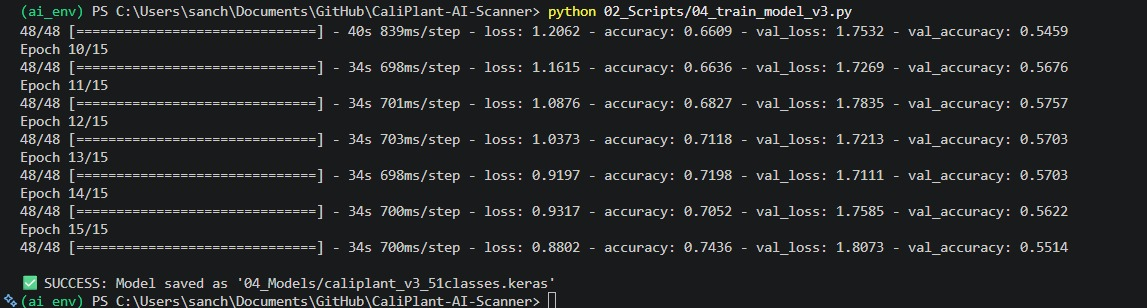

### 3. Residual Performance Plateaus
* **The Feature Stagnation Limit:** Although training loss stabilized and the 51-way classification ran without crashing, the validation accuracy curve hit a hard ceiling and plateaued.

* **Technical Root Cause Analysis:** Because the entire MobileNetV2 feature extractor remained completely locked (base_model.trainable = False), the custom classification head was entirely responsible for learning the mapping. Pre-trained ImageNet filters excel at broad everyday visual distinctions (e.g., animals, vehicles) but lack the highly specialized botanical feature filters needed to separate highly similar plant species.

---

## Intermission: Data Engineering Disasters & Environment Infrastructure Breaks

Prior to advancing the deep learning architecture into active sub-layer unfreezing, one thing that was entirely necessary was the availibility of dataset for training the model and this problem needed to be solved by downloading high quality images from the internet since I have searched various sites but did not get the dataset required also the project environment encountered critical web blocks, file system failures, and OS security restrictions that completely halted operations:

### 1. Automated Scraping Firewall Blocks (HTTP 429 & 403 Crashes)
* **The Infrastructure Failure:** While running programmatic Python `requests` and custom scraping scripts to expand our plant image dataset from web repositories like Wikimedia Commons and iNaturalist, remote servers flagged our high-frequency automated requests. The terminal threw continuous `HTTP 429 (Too Many Requests)` errors followed by strict IP-banning `HTTP 403 (Forbidden)` flags.
* **The Engineering Fix:** Re-engineered the data intake module using the multi-threaded `icrawler` framework. When standard user-agent spoofing failed against strict firewalls, the extraction engine was shifted to run natively over the **DuckDuckGo Image Crawler Engine**, bypassing server layout restrictions and securing clean downloads without tripping automated security flags.

### 2. Multi-Channel Image Tensor Corruption (RGBA/P to RGB Shape Mismatch)
* **The Infrastructure Failure:** A significant percentage of crawled images contained invalid color profiles, transparent alpha channels (`RGBA`), grayscale transparent layers (`LA`), or palette-indexed indices (`P`). Passing these files directly into the TensorFlow dataset iterator triggered fatal tensor shape exceptions because the model graphs expected exactly 3 channels.
* **The Engineering Fix:** Wrote a recursive PIL processing script that scanned the entire local disk tree. It automatically identified alpha layers, stripped transparency by compositing the pixels over a solid white canvas background `(255, 255, 255)`, converted all formats to standard 3-channel JPEGs, and overwrote the files cleanly.

### 3. Local OS PowerShell Security Lockout
* **The Infrastructure Failure:** Activating the project's Python virtual environment (`ai_env`) within VS Code was repeatedly blocked by Windows OS security controls, throwing red execution policy access exceptions.
* **The Engineering Fix:** Applied a temporary, process-scoped administrative override directly into the active session terminal shell: `Set-ExecutionPolicy -ExecutionPolicy RemoteSigned -Scope Process`.

### 4. Catastrophic File System Erasure
* **The Infrastructure Failure:** An accidental workspace cache reset or local directory cleanup mistake completely deleted the `04_Models/` folder from disk, instantly erasing the compiled network weights and checkpoints from versions V1 through V4.
* **The Critical Consequence:** We lost our compiled intermediate model binaries. This forced a strategic design shift—the pipeline had to be configured to handle advanced fine-tuning directly from scratch, bypassing the progressive loading of intermediate model checkpoints.

---

## Phase 4: Model V4 — Fine-Tuning via Selective Backbone Unfreezing

### 1. The Strategy Pivot (Transitioning from Static Extraction to Deep Adaption)
To break past the performance plateaus caused by the generic filters of Model V3, the architecture strategy shifted from standard transfer learning to active Fine-Tuning. The objective was to carefully unfreeze the deepest convolutional blocks of MobileNetV2, allowing backpropagation to modify their pre-trained weights so they could specialize in capturing botanical details.

### 2. Technical Implementation & Selective Layer Locking
* **Loading and Modifying the Graph Network:** Model V3 was re-initialized, and the underlying base model was unlocked. To protect generic visual feature detectors (like basic lines, corners, and edge primitives) located in the early layers of the network, the first 100 layers were structurally frozen, while leaving the remaining deep layers open for parameter updates:
  ```python
  base_model = model.layers[0]
  base_model.trainable = True
  
  # Lock early layers (0 to 100) to preserve core ImageNet feature extractors
  fine_tune_at = 100
  for layer in base_model.layers[:fine_tune_at]:
      layer.trainable = False
* We only want to fine-tune the top layers, not the very bottom ones.
* MobileNetV2 has ~154 layers. We keep the first 100 frozen.

* **Micro-Learning Rate Safeguard:** Running a high learning rate on an unfrozen backbone can trigger gradient explosions that destroy pre-trained weights. To counteract this, the optimizer was recompiled with a highly restricted learning rate:
```python
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001), # Restricted to a 1e-5 learning rate
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

The fine-tuning phase ran for an additional 10 epochs, allowing layers 101 through 154 to adapt their parameters to the botanical details of the dataset.

![WhatsApp Image 2026-06-19 at 2.06.17 PM.jpeg](<attachment:WhatsApp Image 2026-06-19 at 2.06.17 PM.jpeg>)

### 3. Residual Operational Limitations
* **The Static Optimization Risk:** While validation metrics improved, the script lacked real-time safeguards to handle performance plateaus or overfitting during this deep training phase.

* **Technical Root Cause:** Fine-tuning with a hardcoded epoch limit can cause the model to over-optimize on training noise if left unguarded. Additionally, handling image normalization outside the network graph introduced a risk of data scaling mismatches if input preprocessing configurations were altered between scripts.
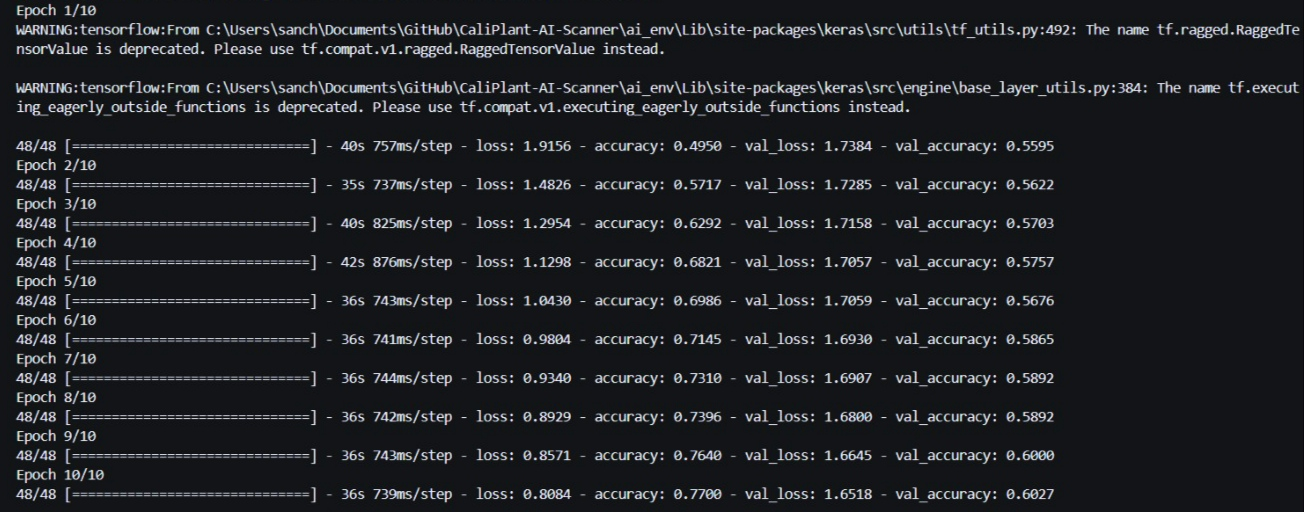

---

## Phase 5: Model V5 — In-Graph Preprocessing, Deep Layer Training & Production Callbacks

### 1. The Strategy Pivot (The Final Production Architecture)
Model V5 represents the most robust and complete iteration of the pipeline, designed to integrate end-to-end data safety, automatic pixel normalization, deeper layer fine-tuning, and dynamic training callbacks. Following the workspace file purge that erased previous intermediate checkpoints, this version was structured to execute advanced fine-tuning safely from a fresh ImageNet initialization.

### 2. High-Fidelity Technical Implementation & Regularization Setup
* **In-Graph Preprocessing Layer Integration:** To eliminate any potential scaling mismatches between data loaders, `tf.keras.applications.mobilenet_v2.preprocess_input` was embedded as the absolute first functional layer in the network graph. This automatically handles scaling incoming raw `0.0 to 1.0` generator arrays to MobileNet's strict expected internal range of `-1.0 to 1.0` natively at runtime.
* **Level 50 Deep Unfreezing:** The unfreezing boundary was pushed significantly deeper than in Model V4. While the first 50 layers remained locked to preserve low-level features, all layers from layer 50 onwards were un-frozen, giving the network 104 trainable convolutional layers to adapt to granular plant characteristics.
* **Structural Architecture Overhaul:** Built using the Keras Functional API, a parametric normalization layer and a larger dropout penalty were introduced to stabilize the network during deep training:
  ```python
  inputs = tf.keras.Input(shape=(224, 224, 3))
  x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)        # In-Graph Scaler
  x = base_model(x, training=True)                                       # Forces BatchNormalization updates during fine-tuning
  x = layers.GlobalAveragePooling2D()(x)
  x = layers.BatchNormalization()(x)                         # Stabilizes covariate shifts across unfrozen updates
  x = layers.Dropout(0.4)(x)                                 # Deactivates 40% of units to prevent over-optimization
  outputs = layers.Dense(num_classes, activation='softmax')(x)
  model = models.Model(inputs, outputs)

```python
# STOP training if accuracy don't improve
early_stop = EarlyStopping(
    monitor='val_accuracy', 
    patience=5, 
    restore_best_weights=True
)

# If accuracy stucks reduce the LR
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.2, 
    patience=3, 
    min_lr=1e-7
)

# Save the best model
checkpoint = ModelCheckpoint(
    "04_Models/caliplant_v5_best.keras", 
    monitor='val_accuracy', 
    save_best_only=True
)

### 3. Dynamic Automation Callbacks System:

* **EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True):** Termines execution automatically if validation accuracy flatlines for 5 consecutive epochs, preventing wasteful compute cycles.

* **ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-7):** Shrinks the learning rate by 80% if the validation loss plateaus, allowing the weights to settle into optimal minimum points.

* **ModelCheckpoint("04_Models/caliplant_v5_best.keras", save_best_only=True):** Monitors validation accuracy to permanently isolate and save only the single absolute best historical performance slice.

### 4. Production Evaluation Metrics
The pipeline concludes with a separate testing phase utilizing a decoupled dataset (03_test) with a locked ```shuffle=False``` constraint to generate unbiased classification reports, confusion matrices, and test accuracy metrics. This setup provides an objective evaluation of the model's performance on completely unseen real-world data.